In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

Function 1

In [2]:
img_color = cv2.imread('woman.png')

def colour_balance(image, r_scale, g_scale, b_scale):
    b, g, r = cv2.split(image)

    b = np.clip(b * b_scale, 0, 255).astype(np.uint8)
    g = np.clip(g * g_scale, 0, 255).astype(np.uint8)
    r = np.clip(r * r_scale, 0, 255).astype(np.uint8)

    return cv2.merge([b, g, r])
def update(r_scale, g_scale, b_scale):
    result = colour_balance(img_color, r_scale, g_scale, b_scale)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Ảnh gốc'); axes[0].axis('off')
    axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'R={r_scale}  G={g_scale}  B={b_scale}')
    axes[1].axis('off')
    plt.tight_layout(); plt.show()

widgets.interact(update,
    r_scale=widgets.FloatSlider(min=0.0, max=3.0, step=0.1, value=1.0, description='R scale'),
    g_scale=widgets.FloatSlider(min=0.0, max=3.0, step=0.1, value=1.0, description='G scale'),
    b_scale=widgets.FloatSlider(min=0.0, max=3.0, step=0.1, value=1.0, description='B scale'),
)

interactive(children=(FloatSlider(value=1.0, description='R scale', max=3.0), FloatSlider(value=1.0, descripti…

<function __main__.update(r_scale, g_scale, b_scale)>

Function 2:

C:\Users\admin\AppData\Local\Temp\ipykernel_18088\3422578493.py:19: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 0].hist(img.ravel(), 256, [0, 256], color='gray')
C:\Users\admin\AppData\Local\Temp\ipykernel_18088\3422578493.py:25: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 1].hist(img_equalized.ravel(), 256, [0, 256], color='steelblue')


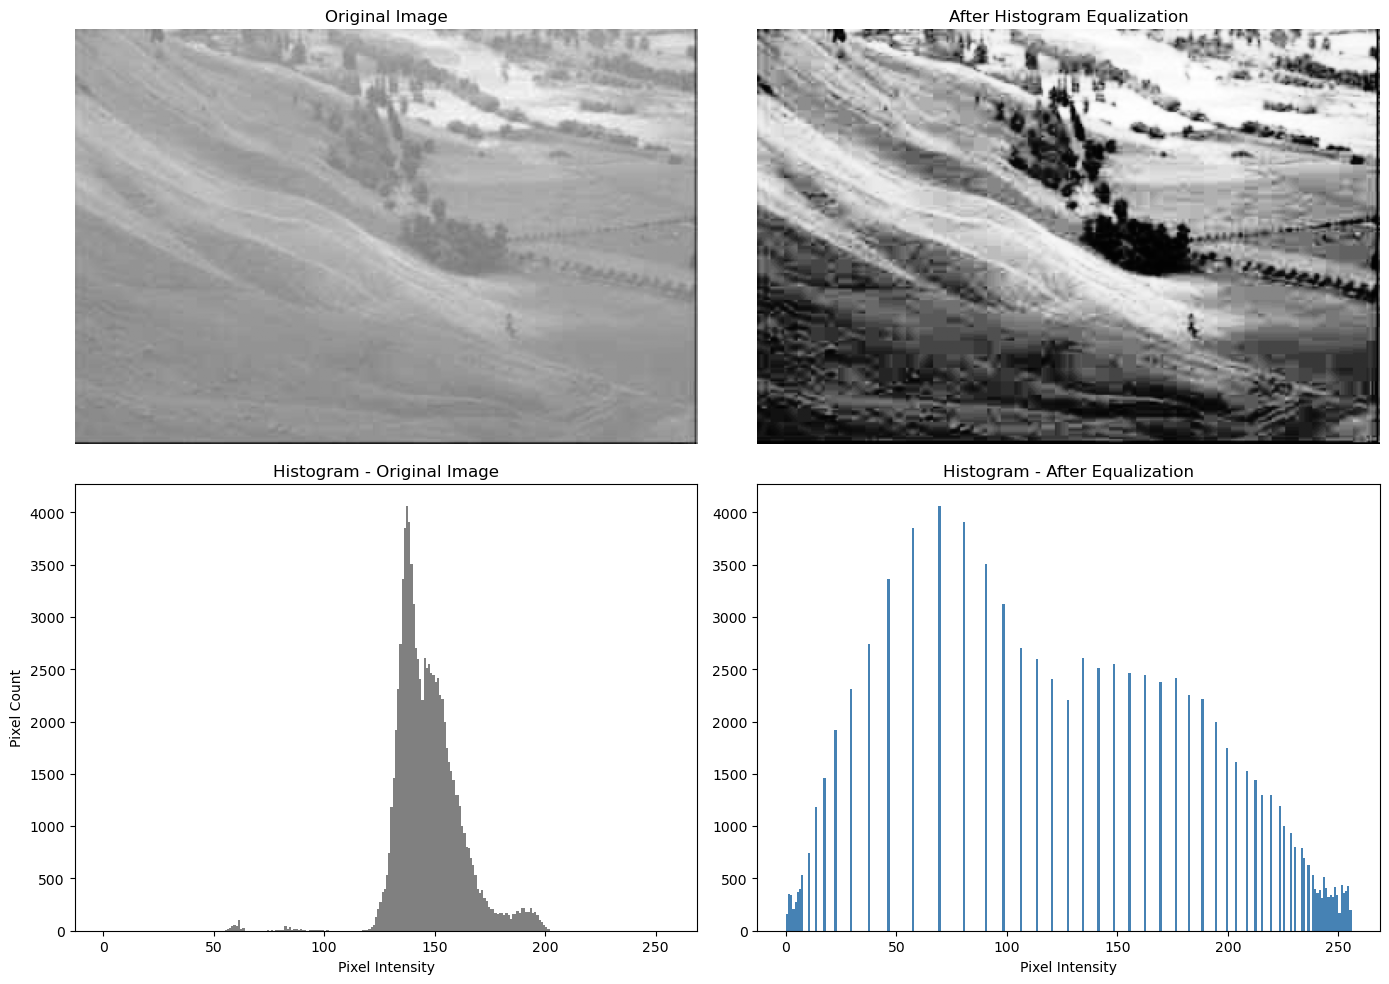

In [3]:
img = cv2.imread('blur.png', cv2.IMREAD_GRAYSCALE)

# Perform Histogram Equalization
img_equalized = cv2.equalizeHist(img)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Original image
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

# Equalized image
axes[0, 1].imshow(img_equalized, cmap='gray')
axes[0, 1].set_title('After Histogram Equalization')
axes[0, 1].axis('off')

# Histogram of original
axes[1, 0].hist(img.ravel(), 256, [0, 256], color='gray')
axes[1, 0].set_title('Histogram - Original Image')
axes[1, 0].set_xlabel('Pixel Intensity')
axes[1, 0].set_ylabel('Pixel Count')

# Histogram after equalization
axes[1, 1].hist(img_equalized.ravel(), 256, [0, 256], color='steelblue')
axes[1, 1].set_title('Histogram - After Equalization')
axes[1, 1].set_xlabel('Pixel Intensity')

plt.tight_layout()
plt.show()

Function 3: 

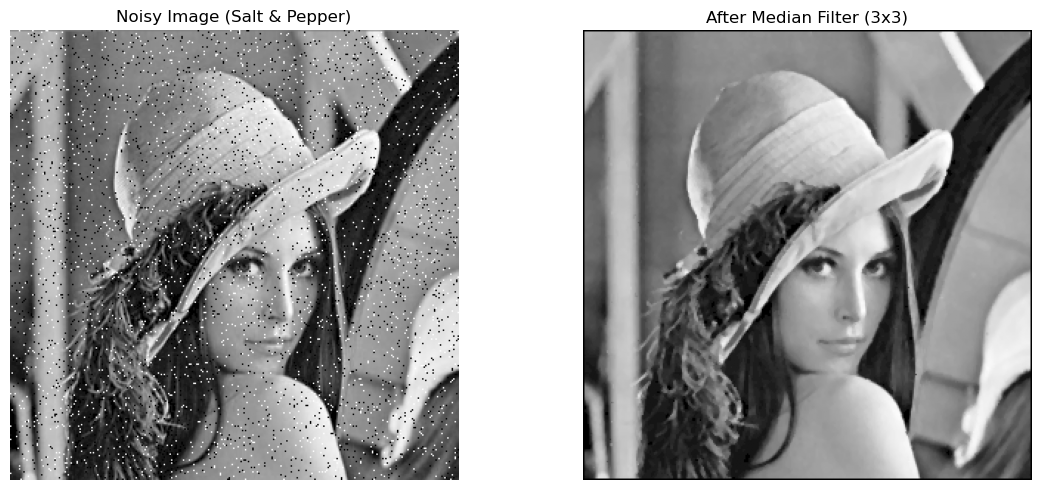

In [4]:
# ── Step 1: Add salt & pepper noise to woman.png ──
def add_salt_pepper_noise(image, noise_ratio=0.05):
    noisy = image.copy()
    H, W = image.shape[:2]
    n = int(noise_ratio * H * W)
    # Salt (white)
    r, c = np.random.randint(0, H, n//2), np.random.randint(0, W, n//2)
    noisy[r, c] = 255
    # Pepper (black)
    r, c = np.random.randint(0, H, n//2), np.random.randint(0, W, n//2)
    noisy[r, c] = 0
    return noisy

# ── Step 2: Median Filter (manual implementation) ──
def median_filter(gray_img, kernel_size=3):
    height, width = gray_img.shape
    offset = kernel_size // 2
    output = np.zeros_like(gray_img, dtype=np.uint8)
    for i in range(offset, height - offset):
        for j in range(offset, width - offset):
            window = gray_img[i-offset:i+offset+1, j-offset:j+offset+1]
            output[i, j] = np.uint8(np.median(window))
    return output

# ── Run ──
img_gray = cv2.imread('woman.png', cv2.IMREAD_GRAYSCALE)
img_noisy = add_salt_pepper_noise(img_gray, noise_ratio=0.05)
img_median = median_filter(img_noisy, kernel_size=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_noisy, cmap='gray')
axes[0].set_title('Noisy Image (Salt & Pepper)')
axes[0].axis('off')
axes[1].imshow(img_median, cmap='gray')
axes[1].set_title('After Median Filter (3x3)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

Function 4:

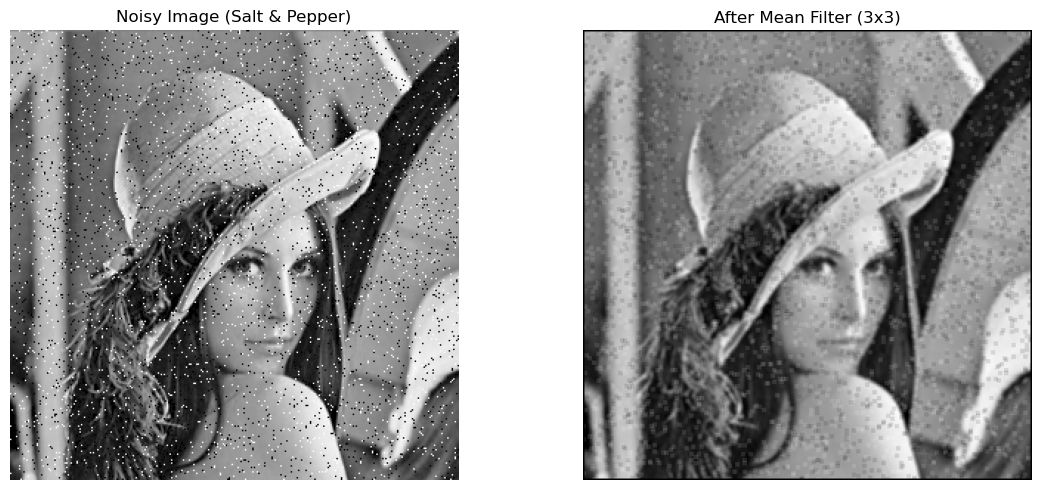

In [5]:
# ── Mean Filter (manual implementation) ──
def mean_filter(gray_img, kernel_size=3):
    height, width = gray_img.shape
    offset = kernel_size // 2
    output = np.zeros_like(gray_img, dtype=np.uint8)
    for i in range(offset, height - offset):
        for j in range(offset, width - offset):
            window = gray_img[i-offset:i+offset+1, j-offset:j+offset+1]
            output[i, j] = np.uint8(np.mean(window))
    return output

# ── Run (reuse img_noisy from Function 3) ──
img_mean = mean_filter(img_noisy, kernel_size=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_noisy, cmap='gray')
axes[0].set_title('Noisy Image (Salt & Pepper)')
axes[0].axis('off')
axes[1].imshow(img_mean, cmap='gray')
axes[1].set_title('After Mean Filter (3x3)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

Function 5:

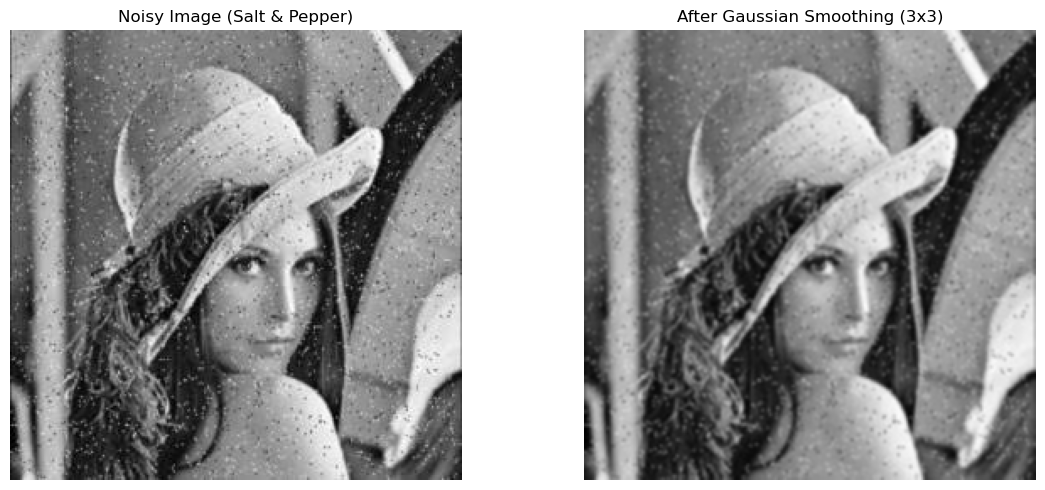

In [6]:
img = cv2.imread('noise.png', cv2.IMREAD_GRAYSCALE)

img_gaussian = cv2.GaussianBlur(img, (3, 3), 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Noisy Image (Salt & Pepper)')
axes[0].axis('off')
axes[1].imshow(img_gaussian, cmap='gray')
axes[1].set_title('After Gaussian Smoothing (3x3)')
axes[1].axis('off')
plt.tight_layout()
plt.show()